In [1]:
import torch

In [2]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

In [5]:
x = torch.linspace(-2, 2, 120).unsqueeze(1)

In [6]:
x

tensor([[-2.0000],
        [-1.9664],
        [-1.9328],
        [-1.8992],
        [-1.8655],
        [-1.8319],
        [-1.7983],
        [-1.7647],
        [-1.7311],
        [-1.6975],
        [-1.6639],
        [-1.6303],
        [-1.5966],
        [-1.5630],
        [-1.5294],
        [-1.4958],
        [-1.4622],
        [-1.4286],
        [-1.3950],
        [-1.3613],
        [-1.3277],
        [-1.2941],
        [-1.2605],
        [-1.2269],
        [-1.1933],
        [-1.1597],
        [-1.1261],
        [-1.0924],
        [-1.0588],
        [-1.0252],
        [-0.9916],
        [-0.9580],
        [-0.9244],
        [-0.8908],
        [-0.8571],
        [-0.8235],
        [-0.7899],
        [-0.7563],
        [-0.7227],
        [-0.6891],
        [-0.6555],
        [-0.6218],
        [-0.5882],
        [-0.5546],
        [-0.5210],
        [-0.4874],
        [-0.4538],
        [-0.4202],
        [-0.3866],
        [-0.3529],
        [-0.3193],
        [-0.2857],
        [-0.

In [15]:

noise = torch.randn_like(x)
y = 3 * x + 2 + noise

In [12]:
import matplotlib.pyplot as plt

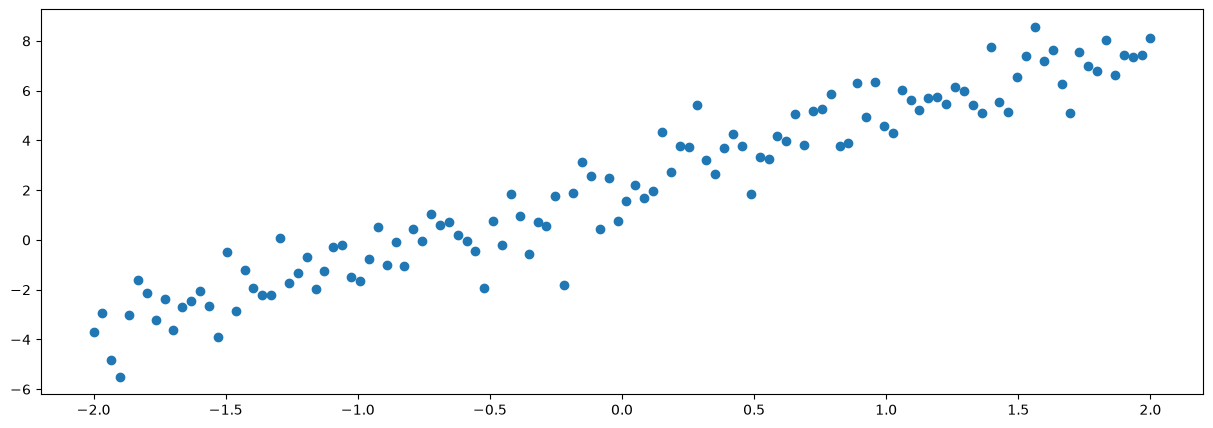

In [16]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)

In [17]:
import torch.nn as nn

In [18]:
model = nn.Linear(1, 1)

In [30]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
epochs = 1000
losses = []
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
    losses.append(loss.item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item()}")
        

Epoch 0, Loss: 0.8889789581298828
Epoch 100, Loss: 0.8889788389205933
Epoch 200, Loss: 0.8889787793159485
Epoch 300, Loss: 0.8889789581298828
Epoch 400, Loss: 0.8889787793159485
Epoch 500, Loss: 0.888978898525238
Epoch 600, Loss: 0.8889788389205933
Epoch 700, Loss: 0.8889789581298828
Epoch 800, Loss: 0.8889787793159485
Epoch 900, Loss: 0.8889789581298828


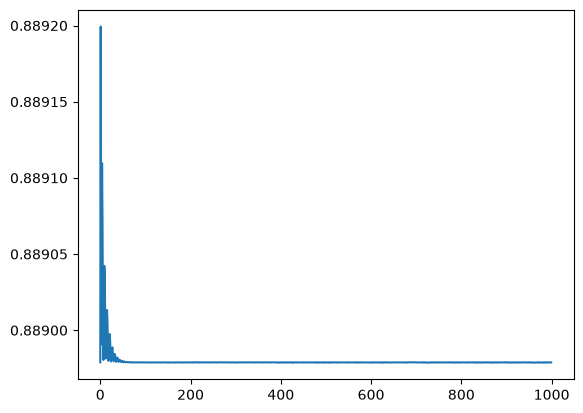

In [31]:
plt.plot(losses)

In [20]:
with torch.inference_mode():
    y_pred = model(x)

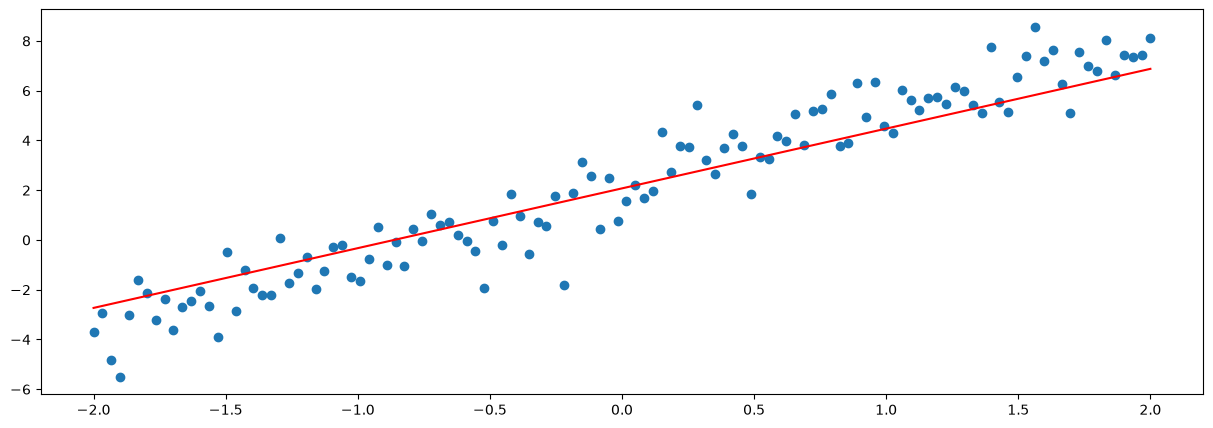

In [21]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y, label="Data")
plt.plot(x, y_pred, color="red", label="Prediction")

In [28]:
from torcheval.metrics import R2Score

In [29]:
r2 = R2Score()
r2.update(y_pred, y)
score = r2.compute()
print(f"R2 Score: {score.item()}")

R2 Score: 0.9288301467895508
